# NCEI OA indicators: the aragonite saturation horizon

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/ocean-icechunks/2026-ioos-hackathon/blob/main/examples/03-oa-saturation-horizon.ipynb)

A textbook ocean acidification picture from NCEI's
[climatology of ocean acidification indicators on the North American margins](https://doi.org/10.25921/g8pb-zy76)
(1° grid, surface to 500 m, observations 2003–2018 adjusted to 2010), as a
[virtual Icechunk store](https://github.com/ocean-icechunks/icechunks/tree/main/oa-indicators).
No credentials needed. Runs on Google Colab (Python 3.12).

## The textbook idea

The ocean takes up about a quarter of the CO₂ that people emit. Dissolved CO₂ forms carbonic acid,
which lowers pH and uses up **carbonate ions** (CO₃²⁻), the building block that corals, pteropods,
oysters and other animals use to make shells of calcium carbonate.

The **aragonite saturation state**, Ω<sub>A</sub>, measures how easy that is:

$$\Omega_A = \frac{[\mathrm{Ca^{2+}}]\,[\mathrm{CO_3^{2-}}]}{K'_{sp}}$$

- Ω<sub>A</sub> > 1: seawater is supersaturated, and aragonite shells can form and persist.
- Ω<sub>A</sub> < 1: seawater is **corrosive**, and unprotected aragonite dissolves.

Ω<sub>A</sub> falls with depth. Deep water is cold and under pressure, both of which make aragonite
more soluble, and it holds CO₂ released by the decay of sinking organic matter. The depth where
Ω<sub>A</sub> = 1 is the **aragonite saturation horizon**. Two things set how deep it is:

- **Ocean basin.** North Pacific deep water is old and has collected respired CO₂ for centuries, so
  its horizon is far shallower than the North Atlantic's.
- **Upwelling.** Along the US West Coast, spring and summer winds bring that corrosive water up onto
  the continental shelf ([Feely et al. 2008](https://doi.org/10.1126/science.1155676)). It was
  behind the oyster-hatchery failures in the Pacific Northwest
  ([Barton et al. 2012](https://doi.org/10.4319/lo.2012.57.3.0698)), and every bit of
  anthropogenic CO₂ raises the horizon further.

## Why the store helps

NCEI ships this product as one NetCDF file per indicator, and the files' latitude, longitude and
depth axes are placeholder zeros, so you cannot select a place or draw a map without rebuilding
the grid by hand. The store puts all 12 indicators on one real `(depth, lat, lon)` grid.

In [ ]:
%pip install -q "icechunk>=2.3" "xarray>=2026.7" "zarr>=3.4" matplotlib

In [2]:
import icechunk, xarray as xr
import matplotlib.pyplot as plt
from matplotlib.patches import Patch

url = "https://data.source.coop/ocean-icechunks/oa-indicators/climatology"
repo = icechunk.Repository.open(icechunk.http_storage(url))
# Authorize anonymous reads of NCEI's files, where the data actually live.
auth = {p: icechunk.credentials.HttpAccess for p in repo.config.virtual_chunk_containers}
repo = repo.reopen(authorize_virtual_chunk_access=auth)
ds = xr.open_zarr(repo.readonly_session("main").store, consolidated=False, chunks=None)
ds

<xarray.Dataset> Size: 86MB
Dimensions:    (depth: 14, lat: 76, lon: 141)
Coordinates:
  * depth      (depth) float64 112B 0.0 10.0 20.0 30.0 ... 300.0 400.0 500.0
  * lat        (lat) float64 608B 10.5 11.5 12.5 13.5 ... 82.5 83.5 84.5 85.5
  * lon        (lon) float64 1kB -179.5 -178.5 -177.5 ... -41.5 -40.5 -39.5
Data variables: (12/72)
    CO3_SE     (depth, lat, lon) float64 1MB ...
    CO3_an     (depth, lat, lon) float64 1MB ...
    CO3_mn     (depth, lat, lon) float64 1MB ...
    DIC_gp     (depth, lat, lon) float64 1MB ...
    DIC_an     (depth, lat, lon) float64 1MB ...
    Hfree_SE   (depth, lat, lon) float64 1MB ...
    ...         ...
    pHT_dd     (depth, lat, lon) float64 1MB ...
    pHT_mn     (depth, lat, lon) float64 1MB ...
    pHT_sd     (depth, lat, lon) float64 1MB ...
    pHT_an     (depth, lat, lon) float64 1MB ...
    fCO2_an    (depth, lat, lon) float64 1MB ...
    pHT_gp     (depth, lat, lon) float64 1MB ...
Attributes: (12/33)
    Conventions:                   CF-1.12, ACDD-1.3
    title:                         Climatological distribution of ocean acidi...
    summary:                       1x1 degree coastal climatologies of twelve...
    keywords:                      ocean acidification, pH, aragonite saturat...
    source:                        NCEI Accession 0270962: twelve NetCDF-4 fi...
    history:                       2026-09-17T22:18:58+00:00: merged the twel...
    ...                            ...
    geospatial_lon_units:          degrees_east
    geospatial_vertical_units:     m
    geospatial_vertical_positive:  down
    time_coverage_start:           2003-12-06
    time_coverage_end:             2018-11-22
    comment:                       A climatology: there is no time dimension....

## Map the saturation horizon

`OmegaA_an` is the analysed aragonite saturation state, 1.2 MB for the whole 3-D field. For each
grid cell, find the shallowest depth where it drops below 1.

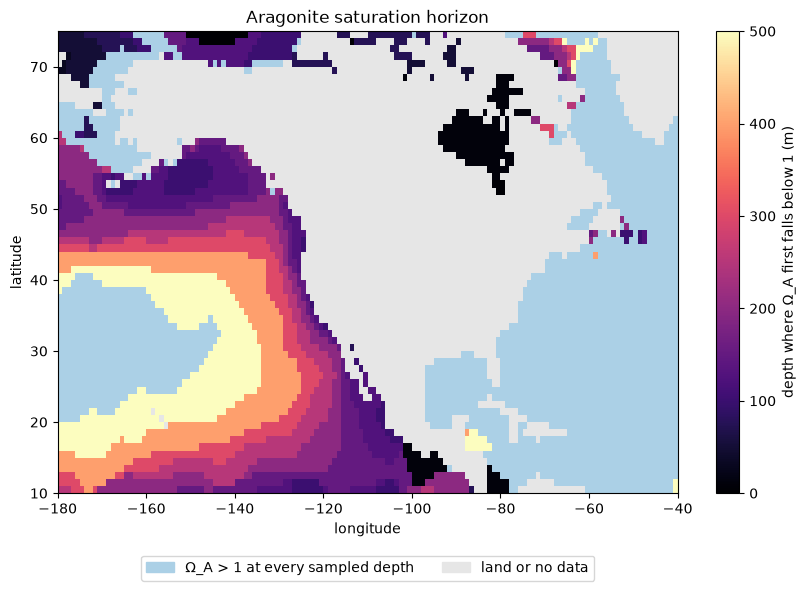

In [3]:
omega = ds.OmegaA_an.load()

corrosive = omega < 1
horizon = corrosive.idxmax("depth").where(corrosive.any("depth"))   # first depth with Ω < 1
not_reached = omega.notnull().any("depth") & ~corrosive.any("depth")

fig, ax = plt.subplots(figsize=(10, 6))
ax.set_facecolor("0.9")                                   # land, and cells with no data
not_reached.where(not_reached).plot(ax=ax, cmap="Blues", vmin=0, vmax=3, add_colorbar=False)
horizon.plot(ax=ax, cmap="magma", vmin=0, vmax=500,
             cbar_kwargs={"label": "depth where Ω_A first falls below 1 (m)"})
ax.legend(handles=[Patch(color=plt.cm.Blues(1 / 3), label="Ω_A > 1 at every sampled depth"),
                   Patch(color="0.9", label="land or no data")],
          loc="upper center", bbox_to_anchor=(0.5, -0.12), ncols=2)
ax.set(title="Aragonite saturation horizon", xlabel="longitude", ylabel="latitude",
       xlim=(-180, -40), ylim=(10, 75))
plt.show()

- **Pacific coast, Mexico to Alaska:** corrosive water sits only 100–150 m down, on or just off
  the shelf. Offshore, in the subtropical gyre, the horizon deepens to 400 m and below 500 m.
- **Atlantic, Gulf of Mexico, Caribbean:** Ω<sub>A</sub> stays above 1 at every depth sampled,
  down to 500 m.
- **Two shallow spots:** off southern Mexico and Central America, where an oxygen-poor,
  CO₂-rich layer lies close under the surface, and Hudson Bay, whose river-fed water is low in
  carbonate; in both, Ω<sub>A</sub> is below 1 within 10–50 m of the surface.

## Two profiles

Oregon's shelf edge against the open Gulf of Mexico. Both start supersaturated at the surface;
only one crosses Ω<sub>A</sub> = 1.

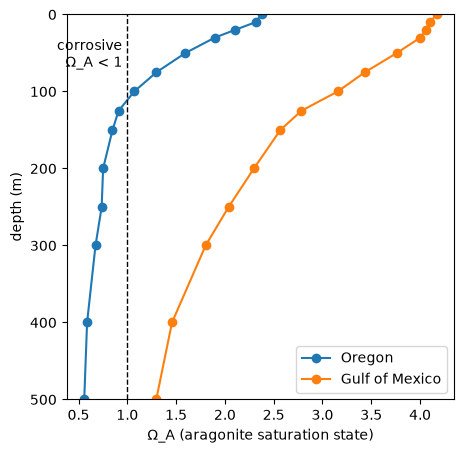

In [4]:
fig, ax = plt.subplots(figsize=(5, 5))
for name, lat, lon in [("Oregon", 44.5, -125.5), ("Gulf of Mexico", 26.5, -90.5)]:
    p = omega.sel(lat=lat, lon=lon, method="nearest")
    ax.plot(p, p.depth, "o-", label=name)
ax.axvline(1, color="k", ls="--", lw=1)
ax.text(0.95, 30, "corrosive\nΩ_A < 1", ha="right", va="top")
ax.set(ylim=(500, 0), xlabel="Ω_A (aragonite saturation state)", ylabel="depth (m)")
ax.legend()
plt.show()

**Caveats.** This is a climatology: observations from 2003–2018, adjusted to the year 2010 and
gridded at 1°, so it smooths seasons and upwelling events, and the horizon is only as fine as the
depth levels (100, 125, 150 m …). `OmegaA_dd` gives the number of observations behind each cell,
useful for judging where the map is well constrained.

**More:** the [store's README](https://github.com/ocean-icechunks/icechunks/tree/main/oa-indicators)
lists all 72 variables (pH, DIC, alkalinity, pCO₂, Revelle factor, …) and how to cite the data.